# ARIMA

## Setup

In [1]:
%load_ext autoreload
%autoreload 2
%load_ext rpy2.ipython

import itertools
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_arch

from src.config import HORIZONS, N_TEST
from src.data_prep import load_and_validate_careggi
from src.diagnostic import ljung_box_table, run_adf_test, run_kpss_test
from src.evaluation import error_metrics, seasonal_naive
from src.models import build_exog, calendar_day_zscores, fit_sarimax_with_exog, rolling_forecast
from src.visualization import plot_acf, plot_forecasts, plot_inverse_roots, plot_pacf, plot_time_series

DATA_DIR = Path("data")
FIG_DIR = Path("figures/arima")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## Data

In [2]:
df = load_and_validate_careggi(DATA_DIR / "PS-Careggi-2013-2020.xlsx")
y = df["x"]
y_train, y_test = y.iloc[:-N_TEST], y.iloc[-N_TEST:]
print(f"Train: {len(y_train)} days ({y_train.index[0].date()} - {y_train.index[-1].date()})")
print(f"Test:  {len(y_test)} days ({y_test.index[0].date()} - {y_test.index[-1].date()})")



Train: 2191 days (2013-01-01 - 2018-12-31)
Test:  365 days (2019-01-01 - 2019-12-31)


# Preliminary analysis

## Plot of the original series 

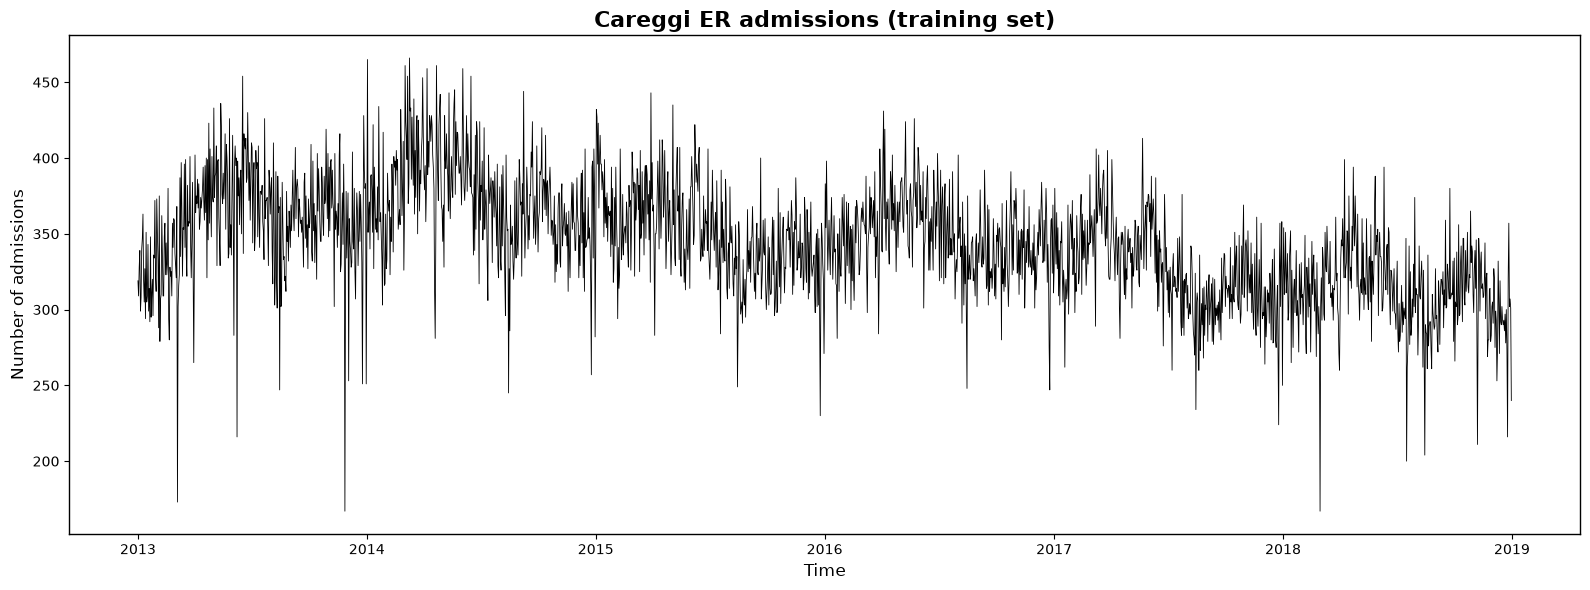

In [3]:
plot_time_series(y_train, title="Careggi ER admissions (training set)", ylabel="Number of admissions",
                save_name=FIG_DIR / "series.png")


## Plot of ACF and PACF

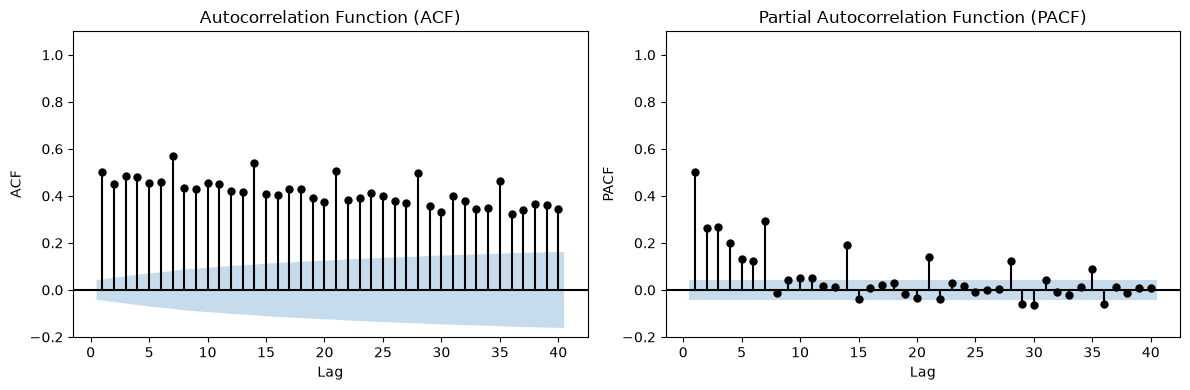

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(y_train, ax=axes[0], ylim=(-0.2, 1.1))
plot_pacf(y_train, ax=axes[1], ylim=(-0.2, 1.1))
fig.tight_layout()
fig.savefig(FIG_DIR / "acf_pacf.png", dpi=300, bbox_inches="tight")
plt.show()

## Estimation of the optimal Lambda with the box-cox function

In [5]:
_, best_lambda = stats.boxcox(y_train)
print(f"Box-Cox lambda: {best_lambda:.4f}")

Box-Cox lambda: 1.2494


## ADF Test

In [6]:
diff_1 = y_train.diff().dropna()
run_adf_test(y_train, title="Levels")
run_kpss_test(y_train, title="Levels")
run_adf_test(diff_1, title="First difference", reg="n")
run_kpss_test(diff_1, title="First difference")


Levels               | ADF stat:   -2.8515 | p-value: 0.0513 | non-stationary
Levels               | KPSS stat:   4.5577 | p-value: < 0.01 | non-stationary
First difference     | ADF stat:  -13.9878 | p-value: 0.0000 | stationary
First difference     | KPSS stat:   0.4413 | p-value: 0.0594 | stationary


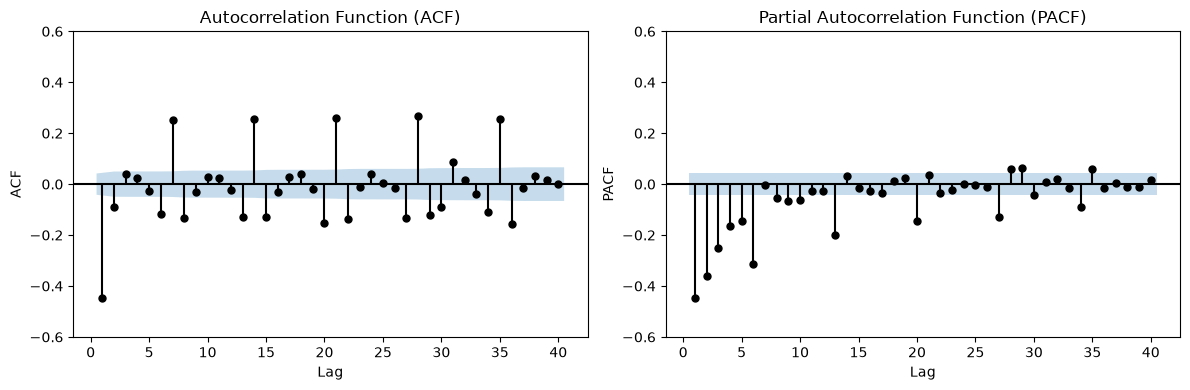

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(diff_1, ax=axes[0], ylim=(-0.6, 0.6))
plot_pacf(diff_1, ax=axes[1], ylim=(-0.6, 0.6))
fig.tight_layout()
fig.savefig(FIG_DIR / "acf_pacf_diff.png", dpi=300, bbox_inches="tight")
plt.show()


# Seasonal ARIMA Modeling
## Base Model fitting

In [8]:
base_results = sm.tsa.SARIMAX(y_train, order=(0, 1, 2), trend="n").fit(disp=False)
print(base_results.summary())

                               SARIMAX Results                                
Dep. Variable:                      x   No. Observations:                 2191
Model:               SARIMAX(0, 1, 2)   Log Likelihood              -10438.375
Date:                mer, 07 ott 2026   AIC                          20882.750
Time:                        18:54:32   BIC                          20899.825
Sample:                    01-01-2013   HQIC                         20888.991
                         - 12-31-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.8608      0.020    -42.169      0.000      -0.901      -0.821
ma.L2         -0.0416      0.021     -1.986      0.047      -0.083      -0.001
sigma2       807.6568     15.683     51.499      0.0

## Calendar effects

In [9]:
full_dates_py = y.index.strftime("%Y-%m-%d").values

In [10]:
%%R -i full_dates_py -o calendar_full_mat -o calendar_names
source("R/CalendarEffects-Student-Functions.R")
source("R/DummySpline-Functions.R")

dates <- as.Date(full_dates_py)
calendar_full_mat <- cbind(.xreg.daily.dummies(date = dates), .xreg.monthly.dummies(date = dates))
calendar_names <- colnames(calendar_full_mat)


Caricamento del pacchetto richiesto: timeDate
Caricamento del pacchetto richiesto: splines2


In [11]:
calendar = pd.DataFrame(calendar_full_mat, index=y.index, columns=list(calendar_names))
calendar_results = fit_sarimax_with_exog(y_train, calendar.iloc[:-N_TEST], order=(0, 1, 2), trend="c")
print(calendar_results.summary())

                               SARIMAX Results                                
Dep. Variable:                      x   No. Observations:                 2191
Model:               SARIMAX(0, 1, 2)   Log Likelihood              -10131.744
Date:                mer, 07 ott 2026   AIC                          20311.488
Time:                        18:54:52   BIC                          20448.087
Sample:                    01-01-2013   HQIC                         20361.414
                         - 12-31-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -0.0063      0.043     -0.145      0.884      -0.091       0.078
Mon           41.5964      1.954     21.289      0.000      37.767      45.426
Tue           11.6444      1.906      6.111      0.0

## Special days

In [12]:
BURN_IN = 7  # with d = 1 the first residual is just the first observation: skip the first week
z = calendar_day_zscores(calendar_results.resid.iloc[BURN_IN:])
print("Over-predicted days:", z.head(10), "", "Under-predicted days:", z.tail(10), sep="\n")

special_days = [(12, 25), (8, 15), (12, 31), (12, 24), (1, 2), (12, 27)]
print("\nSpecial days (month, day):", special_days)

exog = build_exog(calendar, special_days)
exog_train, exog_test = exog.iloc[:-N_TEST], exog.iloc[-N_TEST:]


Over-predicted days:
           mean_resid         z
month day                      
8     15   -65.558753 -5.348555
12    31   -64.403309 -5.254327
      25   -62.132257 -5.069119
      24   -33.908245 -2.767413
3     1    -28.303135 -2.310308
11    27   -26.922081 -2.197682
12    3    -23.858831 -1.947869
6     8    -23.035868 -1.880756
1     18   -21.890747 -1.787369
      14   -21.874831 -1.786071

Under-predicted days:
           mean_resid         z
month day                      
6     2     21.188208  1.725778
11    1     21.484101  1.749909
10    27    21.866975  1.781133
2     28    21.895251  1.783439
3     21    23.911621  1.947876
2     13    25.150079  2.048874
8     1     25.563497  2.082589
1     2     43.136515  3.515693
12    27    45.883023  3.739674
      26    50.885076  4.147598

Special days (month, day): [(12, 25), (8, 15), (12, 31), (12, 24), (1, 2), (12, 27)]


## Model with outliers and calendar effects

In [13]:
rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for p, q in itertools.product(range(3), range(3)):
        res = sm.tsa.SARIMAX(y_train, exog=exog_train, order=(p, 1, q), trend="n").fit(disp=False, maxiter=500)
        rows.append({"order": f"({p},1,{q})", "AIC": res.aic, "BIC": res.bic})
print(pd.DataFrame(rows).sort_values("AIC").round(2).to_string(index=False))


  order      AIC      BIC
(2,1,2) 20107.62 20272.68
(0,1,2) 20109.01 20262.69
(1,1,1) 20109.25 20262.93
(1,1,2) 20114.85 20274.22
(2,1,1) 20115.93 20275.29
(0,1,1) 20128.07 20276.05
(2,1,0) 20521.08 20674.75
(1,1,0) 20740.81 20888.80
(0,1,0) 21195.35 21337.64


In [14]:
final_results = fit_sarimax_with_exog(y_train, exog_train, order=(0, 1, 2), trend="n")
print(final_results.summary())
# 26 Dec is excluded: its high z-score only reflects the rebound after 25 Dec,
# and its dummy is not significant once 25 Dec has its own
check = fit_sarimax_with_exog(
    y_train, build_exog(calendar, special_days + [(12, 26)]).iloc[:-N_TEST], order=(0, 1, 2)
)
se_hessian = pd.Series(np.sqrt(np.diag(check.cov_params_approx)), index=check.params.index)
p_hessian = 2 * stats.norm.sf(abs(check.params["26_dec"] / se_hessian["26_dec"]))
print(f"p-value 26_dec: OPG {check.pvalues['26_dec']:.3f} | Hessian {p_hessian:.3f}")

                               SARIMAX Results                                
Dep. Variable:                      x   No. Observations:                 2191
Model:               SARIMAX(0, 1, 2)   Log Likelihood              -10027.486
Date:                mer, 07 ott 2026   AIC                          20108.971
Time:                        18:58:50   BIC                          20262.646
Sample:                    01-01-2013   HQIC                         20165.139
                         - 12-31-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
25_dec       -86.9089     17.706     -4.908      0.000    -121.612     -52.205
15_aug       -84.1847     15.934     -5.283      0.000    -115.415     -52.954
31_dec       -57.3350     10.434     -5.495      0.0

p-value 26_dec: OPG 0.130 | Hessian 0.053


# Residual Diagnostics

In [15]:
resid = final_results.resid.iloc[BURN_IN:]
print(ljung_box_table(resid, model_df=2, lags=(5, 10, 15, 20, 30)))

     Q statistic  p-value
Lag                      
5          3.004    0.391
10         4.258    0.833
15         6.656    0.919
20        16.763    0.539
30        39.598    0.072


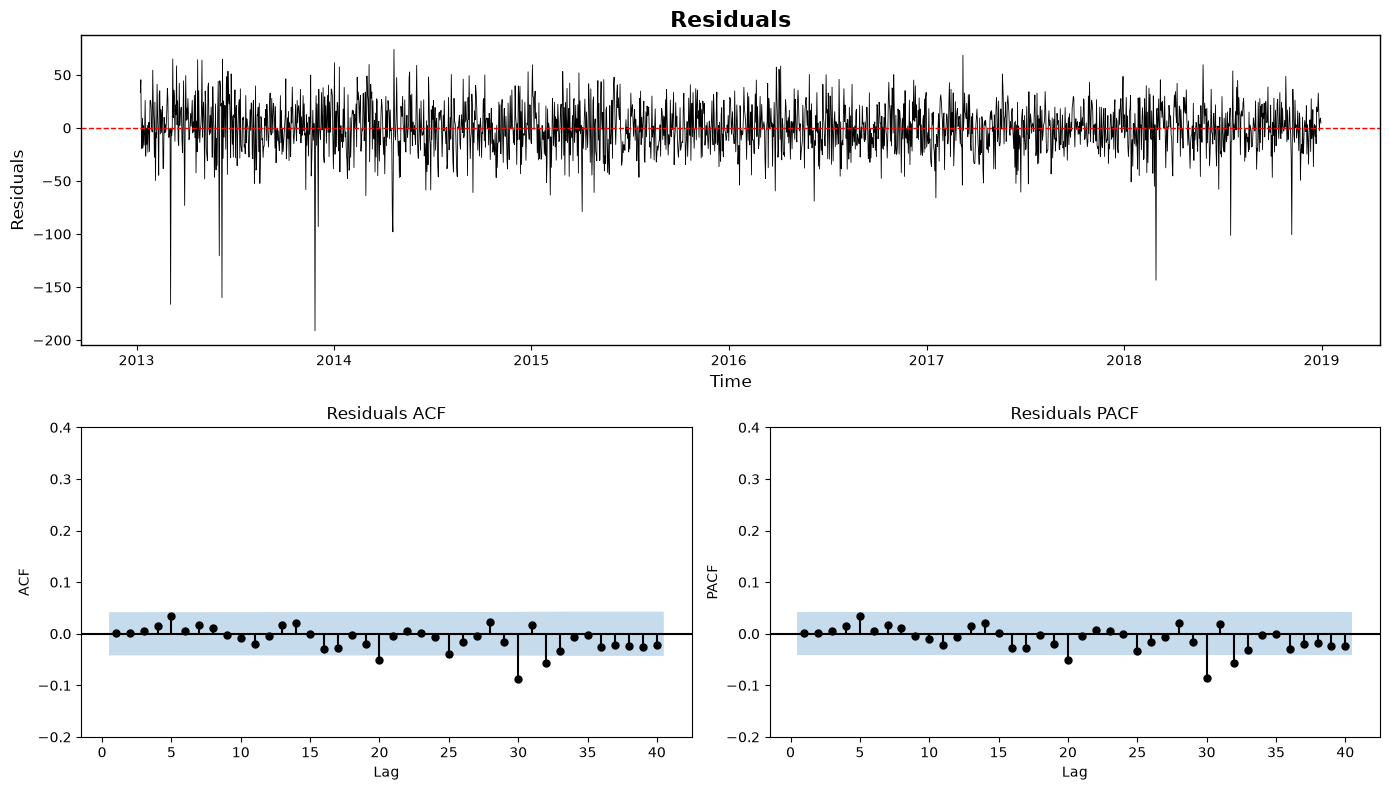

In [16]:
fig = plt.figure(figsize=(14, 8))
ax1 = fig.add_subplot(2, 1, 1)
ax2 = fig.add_subplot(2, 2, 3)
ax3 = fig.add_subplot(2, 2, 4)
plot_time_series(resid, title="Residuals", ylabel="Residuals", ax=ax1)
ax1.axhline(0, color="red", linestyle="--", linewidth=1)
plot_acf(resid, title="Residuals ACF", ylim=(-0.2, 0.4), ax=ax2)
plot_pacf(resid, title="Residuals PACF", ylim=(-0.2, 0.4), ax=ax3)
fig.tight_layout()
fig.savefig(FIG_DIR / "residuals.png", dpi=300, bbox_inches="tight")
plt.show()


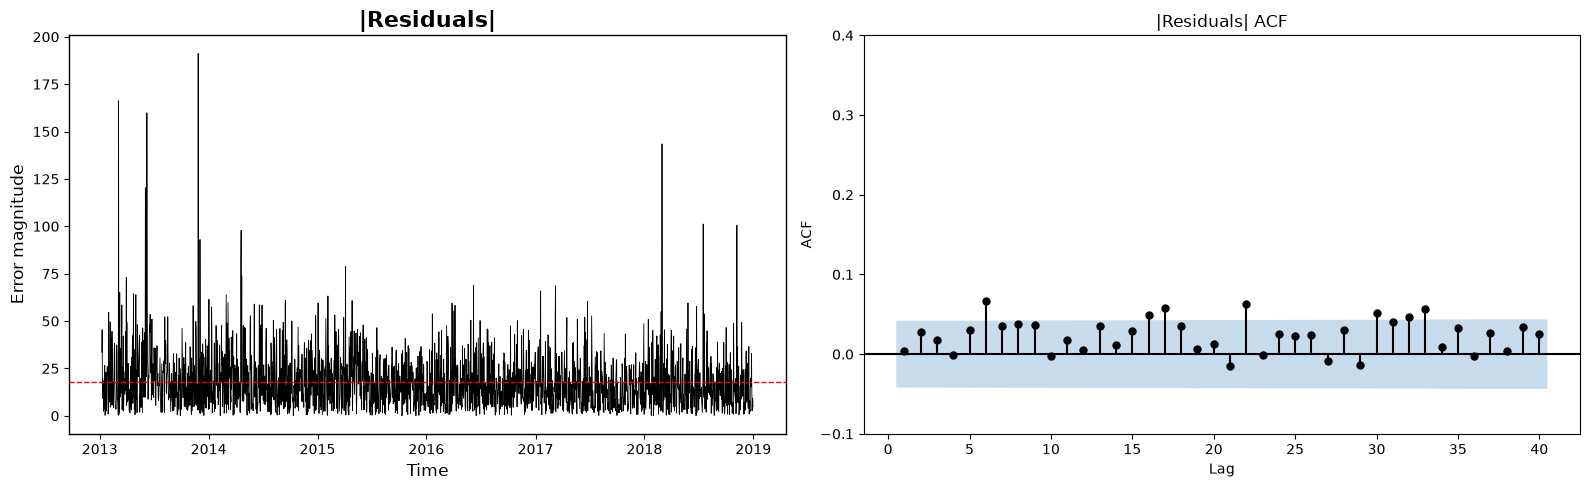

In [17]:
abs_resid = resid.abs()
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_time_series(abs_resid, title="|Residuals|", ylabel="Error magnitude", ax=axes[0])
axes[0].axhline(abs_resid.mean(), color="red", linestyle="--", linewidth=1)
plot_acf(abs_resid, title="|Residuals| ACF", ylim=(-0.1, 0.4), ax=axes[1])
fig.tight_layout()
fig.savefig(FIG_DIR / "abs_residuals.png", dpi=300, bbox_inches="tight")
plt.show()

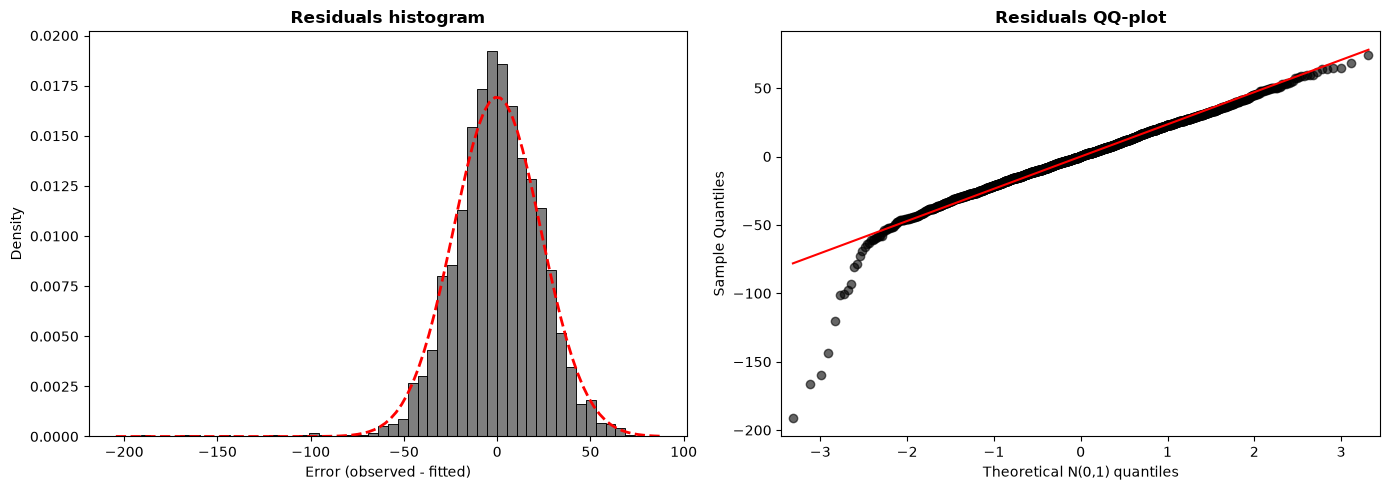

ARCH test (10 lags): LM = 31.09, p-value = 0.0006


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(resid, stat="density", bins=50, color="black", alpha=0.5, ax=axes[0])
x = np.linspace(*axes[0].get_xlim(), 100)
axes[0].plot(x, stats.norm.pdf(x, resid.mean(), resid.std()), color="red", linewidth=2, linestyle="--")
axes[0].set_title("Residuals histogram", fontweight="bold")
axes[0].set_xlabel("Error (observed - fitted)")
axes[0].set_ylabel("Density")
sm.qqplot(resid, line="s", ax=axes[1], markerfacecolor="black", markeredgecolor="black", alpha=0.6)
axes[1].set_title("Residuals QQ-plot", fontweight="bold")
axes[1].set_xlabel("Theoretical N(0,1) quantiles")
fig.tight_layout()
fig.savefig(FIG_DIR / "residuals_hist_qq.png", dpi=300, bbox_inches="tight")
plt.show()

arch_stat, arch_pvalue = het_arch(resid, nlags=10)[:2]
print(f"ARCH test (10 lags): LM = {arch_stat:.2f}, p-value = {arch_pvalue:.4f}")


## Root Analysis

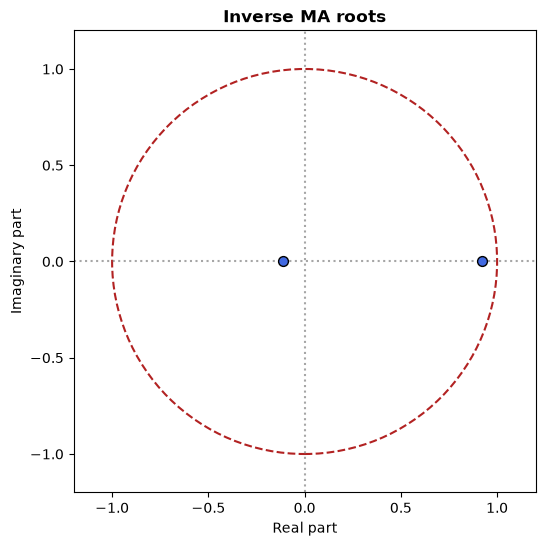

Modulus of the inverse MA roots: [0.922 0.115]


In [19]:
fig, ax = plt.subplots(figsize=(6, 6))
plot_inverse_roots(final_results.maroots, ax, "Inverse MA roots")
fig.tight_layout()
fig.savefig(FIG_DIR / "inverse_ma_roots.png", dpi=300, bbox_inches="tight")
plt.show()
print("Modulus of the inverse MA roots:", np.abs(1 / final_results.maroots).round(3))


# Ex-Post Forecast

In [20]:
arima_fc = {h: rolling_forecast(final_results, y, exog, N_TEST, h) for h in HORIZONS}

rows = []
for h in HORIZONS:
    arima = error_metrics(y_test, arima_fc[h]["forecast"])
    naive = error_metrics(y_test, seasonal_naive(y, N_TEST, h))
    rows.append({"h": h, "RMSE ARIMA": arima["RMSE"], "RMSE naive": naive["RMSE"],
                "MAE ARIMA": arima["MAE"], "MAE naive": naive["MAE"]})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 h  RMSE ARIMA  RMSE naive  MAE ARIMA  MAE naive
 1      20.346      29.482     16.223     22.156
 3      20.661      29.482     16.398     22.156
 7      21.000      29.482     16.747     22.156
14      21.644      32.918     17.229     25.493
30      22.514      32.594     18.010     25.699


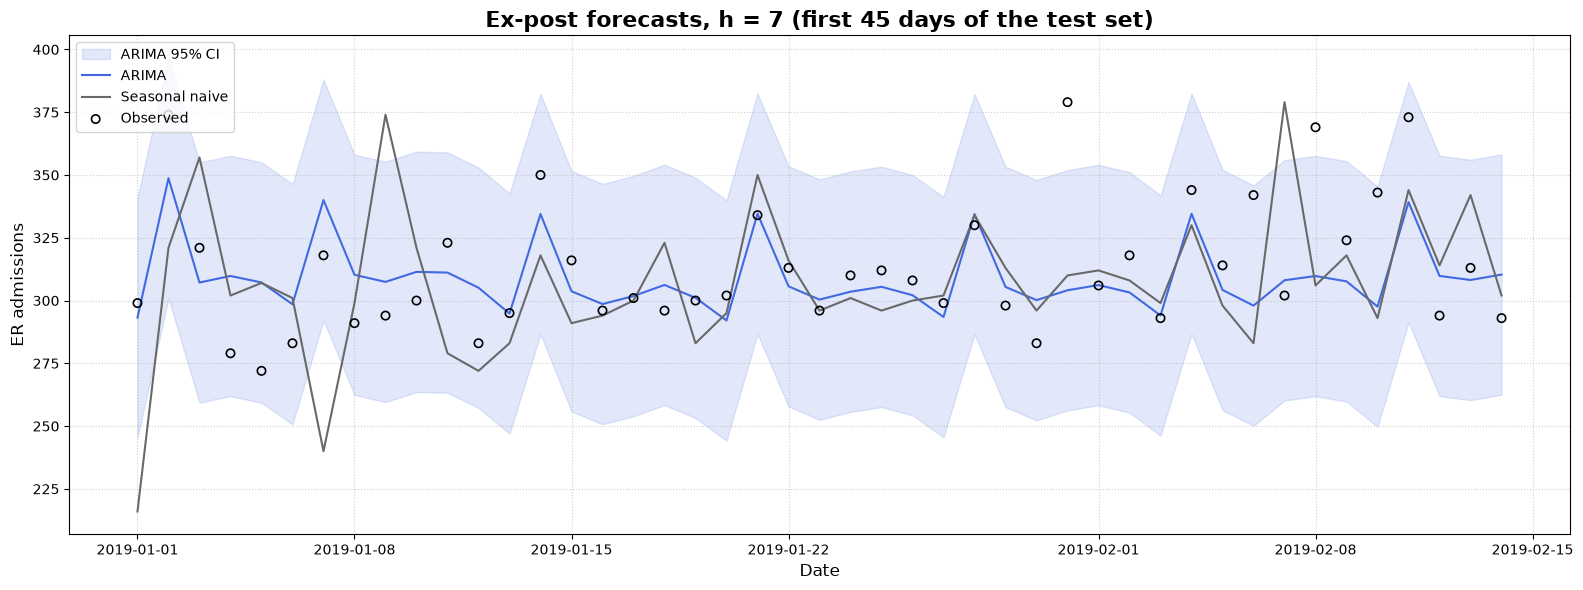

In [21]:
h, days = 7, 45
fc = arima_fc[h].iloc[:days]
plot_forecasts(
    y_test.iloc[:days],
    pd.DataFrame({"ARIMA": fc["forecast"], "Seasonal naive": seasonal_naive(y, N_TEST, h).iloc[:days]}),
    title=f"Ex-post forecasts, h = {h} (first {days} days of the test set)",
    interval=(fc["lower"], fc["upper"]),
    save_name=FIG_DIR / f"ex_post_h{h}.png",
)

In [22]:
pd.concat([y, exog], axis=1).to_csv(DATA_DIR / "model_data.csv", index_label="date")
pd.DataFrame({f"ARIMA_h{h}": fc["forecast"] for h, fc in arima_fc.items()}).to_csv(
    DATA_DIR / "arima_forecasts.csv", index_label="date"
)